# Lab 8: InSAR — Seeing Faults from Space

> **Colab note:** This notebook is designed to run on **Google Colab**. [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amtseismo/EPS166/blob/main/notebooks/08_insar.ipynb)

## Introduction

InSAR interferograms are among the most information-rich geodetic observables we have — a single image can contain millions of displacement measurements across an entire fault system. But reading an interferogram takes practice. The pattern of interference fringes encodes fault geometry, slip magnitude, and depth in ways that are not always intuitive.

In this lab you will work with real Sentinel-1 InSAR data from the 2019 Ridgecrest M7.1 earthquake, processed by Xu, Sandwell, and Smith-Konter (2019). You will learn to read interferogram fringe patterns, understand how the satellite viewing geometry shapes what you see, build synthetic interferograms using elastic dislocation theory, and compare InSAR observations to the GNSS coseismic offsets from Lab 4.

## Learning objectives

By the end of this lab you will be able to:

- read an InSAR interferogram and convert fringe counts to line-of-sight displacement
- explain how the satellite viewing geometry (ascending vs. descending, incidence angle) shapes the observed fringe pattern
- recognize the characteristic patterns of strike-slip, normal, and thrust faults
- build a synthetic interferogram from fault parameters using elastic dislocation theory
- compare InSAR and GNSS observations of the same earthquake

## Notebook outline
1. [Part I: Reading a real interferogram](#part-i-reading-a-real-interferogram)
2. [Part II: LOS geometry](#part-ii-los-geometry)
3. [Part III: Ascending vs. descending](#part-iii-ascending-vs-descending)
4. [Part IV: Forward model](#part-iv-forward-model)
5. [Part V: Profile and GNSS comparison](#part-v-profile-and-gnss-comparison)
6. [Synthesis](#synthesis)


## Setup

Install `cutde` and import the packages used throughout this lab.

In [1]:
%pip install -q cutde

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
import cutde.halfspace as hs
import urllib.request, os, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 130, 'axes.grid': False})
print('Setup complete.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 907.0/907.0 kB 9.1 MB/s eta 0:00:00
Setup complete.


## Data

Download the Sentinel-1 LOS displacement files and GNSS offsets.

In [2]:
files = {
    't71':    'https://raw.githubusercontent.com/amtseismo/EPS166/42acb3ecf5e0101917a21ff474dea4f3c921c974/datasets/Ridgecrest_INSAR_2019/S1_los_T071.lltnde',
    't64':    'https://raw.githubusercontent.com/amtseismo/EPS166/42acb3ecf5e0101917a21ff474dea4f3c921c974/datasets/Ridgecrest_INSAR_2019/S1_los_T064.lltnde',
    't71_ds': 'https://raw.githubusercontent.com/amtseismo/EPS166/42acb3ecf5e0101917a21ff474dea4f3c921c974/datasets/Ridgecrest_INSAR_2019/t71_des_s1.lltnde',
    't64_ds': 'https://raw.githubusercontent.com/amtseismo/EPS166/42acb3ecf5e0101917a21ff474dea4f3c921c974/datasets/Ridgecrest_INSAR_2019/t64_asc_s1.lltnde',
    'gnss':   'https://raw.githubusercontent.com/amtseismo/EPS166/42acb3ecf5e0101917a21ff474dea4f3c921c974/datasets/Ridgecrest_GNSS_2019/unr_static_offsets.txt',
}

for key, url in files.items():
    fname = url.split('/')[-1]
    if not os.path.exists(fname):
        print(f'Downloading {fname} ...', end=' ', flush=True)
        urllib.request.urlretrieve(url, fname)
        print('done')
    else:
        print(f'{fname} already present')

# Store local filenames for later cells
local = {k: v.split('/')[-1] for k, v in files.items()}


In [3]:
def load_lltnde(path):
    """
    Load a .lltnde file (Xu et al. format):
    lon  lat  elev(m)  look_E  look_N  look_U  disp(mm)  error
    Positive displacement = motion toward the satellite.
    """
    d = np.loadtxt(path)
    return dict(lon=d[:,0], lat=d[:,1], elev=d[:,2],
                look_E=d[:,3], look_N=d[:,4], look_U=d[:,5],
                disp=d[:,6], err=d[:,7])

t71 = load_lltnde(local['t71'])
t64 = load_lltnde(local['t64'])

for label, d in [('T71 descending', t71), ('T64 ascending', t64)]:
    print(f'{label}: {len(d["lon"]):,} points')
    print(f'  Lon [{d["lon"].min():.3f}, {d["lon"].max():.3f}]  '
          f'Lat [{d["lat"].min():.3f}, {d["lat"].max():.3f}]')
    print(f'  LOS range: [{d["disp"].min():.0f}, {d["disp"].max():.0f}] mm')
    print(f'  Mean look vector: E={d["look_E"].mean():.3f}  '
          f'N={d["look_N"].mean():.3f}  U={d["look_U"].mean():.3f}')
    print()


T71 descending: 39,481 points
  Lon [-118.027, -116.823]  Lat [35.212, 36.317]
  LOS range: [-1294, 1009] mm
  Mean look vector: E=0.622  N=-0.111  U=0.774

T64 ascending: 39,380 points
  Lon [-118.356, -117.179]  Lat [35.101, 36.228]
  LOS range: [-783, 935] mm
  Mean look vector: E=-0.623  N=-0.111  U=0.774



In [4]:
def grid_los(d, res=0.005):
    """Interpolate scattered LOS data onto a regular lon/lat grid."""
    lon_g = np.arange(d['lon'].min(), d['lon'].max() + res, res)
    lat_g = np.arange(d['lat'].min(), d['lat'].max() + res, res)
    LON, LAT = np.meshgrid(lon_g, lat_g)
    DIS = griddata((d['lon'], d['lat']), d['disp'], (LON, LAT), method='linear')
    return LON, LAT, DIS

print('Gridding T71 ...', end=' ', flush=True)
LON71, LAT71, DIS71 = grid_los(t71)
print('done')


Gridding T71 ... done


## Part I: Reading a real interferogram

The Ridgecrest M7.1 earthquake ruptured the ground surface along a ~50 km NW-SE trending fault on 6 July 2019. The data below come from Sentinel-1 descending track T71, which acquired images on 4 July and 16 July 2019. The displacement field therefore captures the combined coseismic offset of both the M6.4 foreshock and M7.1 mainshock, plus any early postseismic motion in the first ten days.

**Satellite geometry:** Sentinel-1 is a right-looking satellite — the radar antenna points to the right of the flight direction. On a descending pass the satellite flies roughly southward, so it looks to the right — toward the **west**. This means the satellite is positioned to the **east** of the scene and looks westward toward the ground. The look vector stored in the data file (look_E, look_N, look_U) points from the ground toward the satellite: you can confirm that look_E ≈ +0.65 (satellite is to the east), look_U ≈ +0.74 (satellite is above), and look_N ≈ −0.11 (slight southward tilt).

**Sign convention:** positive LOS displacement means the ground moved toward the satellite. Since the satellite is to the east, eastward ground motion produces positive (red) LOS signal and westward motion produces negative (blue) signal. The data page from Xu et al. confirms this: for the descending track, red indicates motion up or east.

We display two versions of the same data below. The **left panel** shows the unwrapped LOS displacement — a continuous map of how far each pixel moved toward or away from the satellite. The **right panel** shows the wrapped phase — the same data folded into repeating color cycles, which is how a real interferogram looks before phase unwrapping. Each complete color cycle represents 2.8 cm of LOS displacement (half the C-band radar wavelength of 5.6 cm).


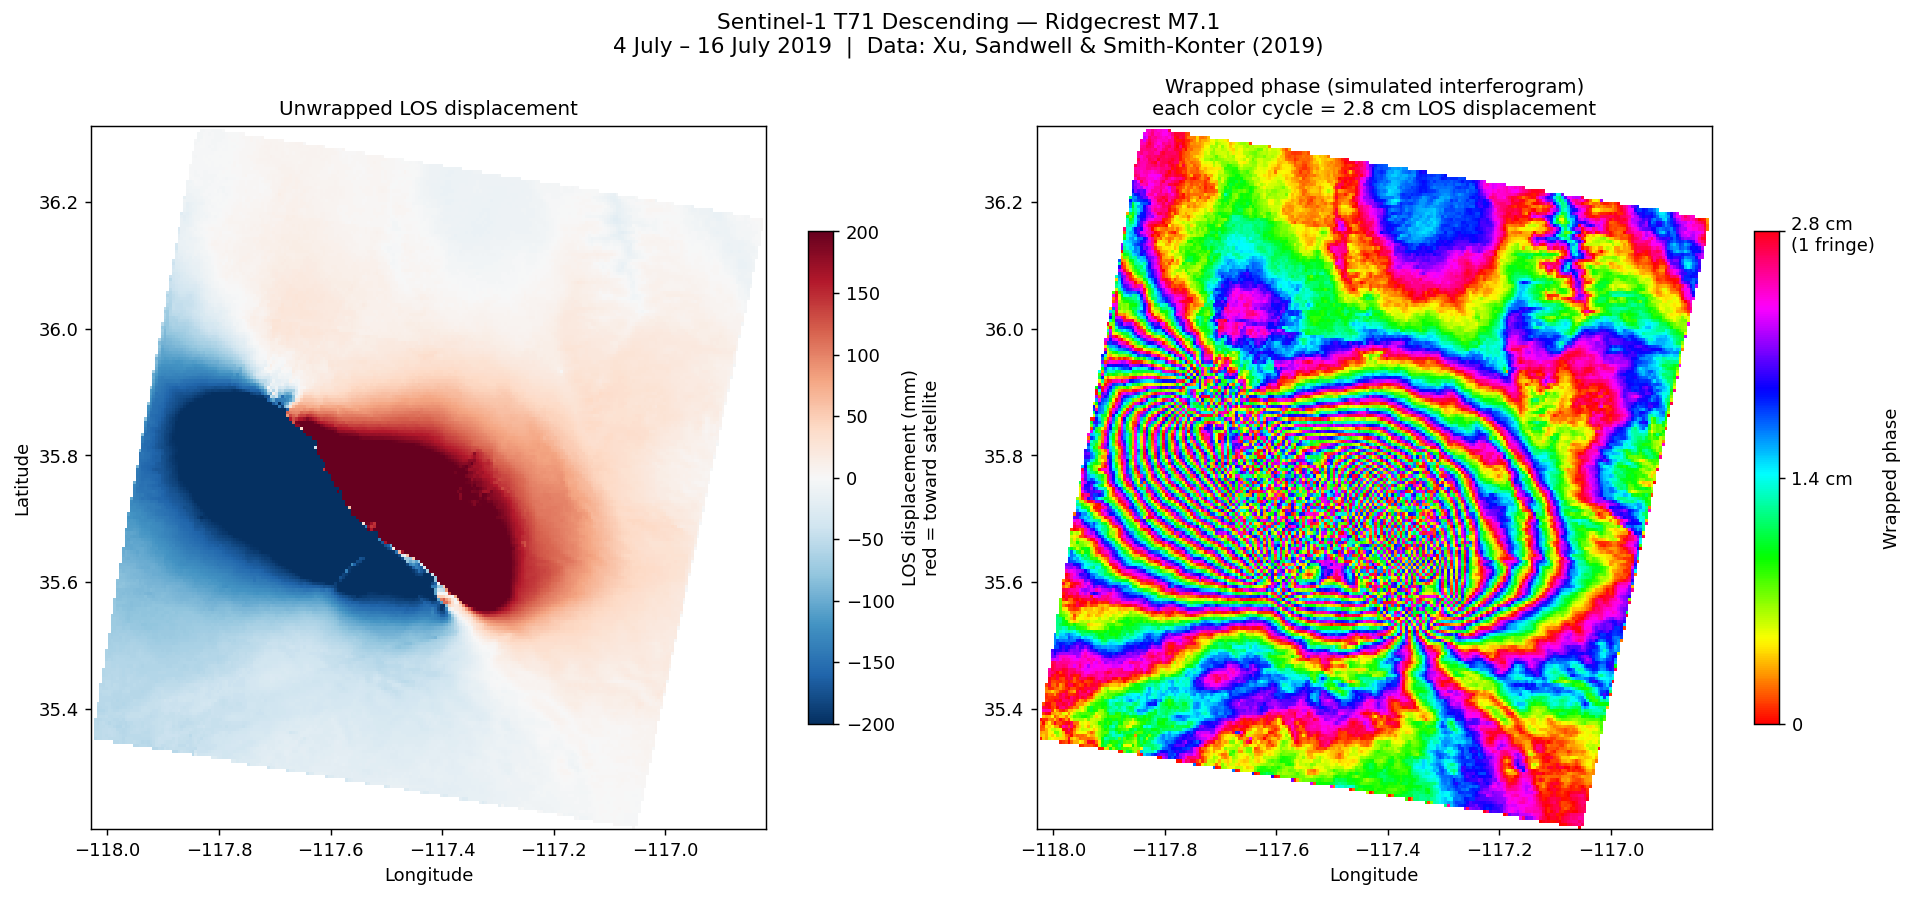

In [5]:
FRINGE_MM = 28.0    # C-band Sentinel-1: lambda/2 = 2.8 cm per fringe
CLIM      = 200     # color scale limit in mm

# Wrap displacement to [0, 1) to simulate a fringe pattern
wrapped71 = (DIS71 / FRINGE_MM) % 1.0

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left: unwrapped LOS
im0 = axes[0].pcolormesh(LON71, LAT71, DIS71, cmap='RdBu_r',
                          vmin=-CLIM, vmax=CLIM, shading='auto')
cbar0 = plt.colorbar(im0, ax=axes[0], shrink=0.7)
cbar0.set_label('LOS displacement (mm)\nred = toward satellite')
axes[0].set_title('Unwrapped LOS displacement', fontsize=11)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')

# Right: wrapped phase (simulated interferogram)
im1 = axes[1].pcolormesh(LON71, LAT71, wrapped71, cmap='hsv',
                          vmin=0, vmax=1, shading='auto')
cbar1 = plt.colorbar(im1, ax=axes[1], shrink=0.7)
cbar1.set_label('Wrapped phase')
cbar1.set_ticks([0, 0.5, 1])
cbar1.set_ticklabels(['0', '1.4 cm', '2.8 cm\n(1 fringe)'])
axes[1].set_title('Wrapped phase (simulated interferogram)\n'
                   'each color cycle = 2.8 cm LOS displacement', fontsize=11)
axes[1].set_xlabel('Longitude')

plt.suptitle('Sentinel-1 T71 Descending — Ridgecrest M7.1\n'
             '4 July – 16 July 2019  |  Data: Xu, Sandwell & Smith-Konter (2019)',
             fontsize=12)
plt.tight_layout()
plt.show()


> **Questions — reading the interferogram:**
> 1. The T71 descending satellite is to the east of the scene, looking westward. The M7.1 was a right-lateral strike-slip fault striking NW-SE. The east block moved roughly southeastward and the west block moved roughly northwestward. Which block moved toward the satellite, and which moved away? Is the red/blue pattern in the LOS map consistent with this?
The east block moved toward the satellite, while the west block moved away, which is consistent with the pattern in the LOS map.
> 2. Using the wrapped phase panel as your interferogram, pick a reference area far from the fault where displacement is effectively zero. Count the number of complete color cycles from that reference to the area of peak displacement on each side of the fault. How many fringes do you count, and what peak LOS displacement does this correspond to in centimeters?
I count about 14 fringes on the southwest side, and 7 on the northeast, which corresponds to ~39 and ~20 cm of LOS displacement.
> 3. Fringe density — how tightly the color cycles are packed — reflects the displacement gradient. Where are the fringes densest, and what does this tell you about where the displacement gradient is steepest?
The fringes are densest closest to the fault, meaning the displacement gradient is steepest there.
> 4. The lecture described two main noise sources in InSAR: atmospheric delay and decorrelation. Look at the far-field region far from the fault. Do you see any broad, smooth signal not obviously related to the earthquake? Near the fault trace, do the fringes become indistinct or noisy anywhere? What might cause this?
Yes, especially in the northwestern corner of the map there are broad circular fringes not related to motion on the fault. Near the fault, the fringes become very indistinct, which could be caused by small-wavelength fracturing or liquefaction features.

## Part II: LOS geometry

InSAR does not measure 3D displacement — it measures a single scalar: the component of ground motion in the direction from the ground to the satellite. This line-of-sight (LOS) displacement is:

$$\Delta \text{LOS} = \hat{e}_E \, \Delta u_E + \hat{e}_N \, \Delta u_N + \hat{e}_U \, \Delta u_U$$

where $\hat{e}_E$, $\hat{e}_N$, $\hat{e}_U$ are the components of the unit look vector (stored per pixel in the data file) and $\Delta u_E$, $\Delta u_N$, $\Delta u_U$ are the east, north, and up components of actual ground displacement.

The bar chart below shows the three look vector components for each track. Think of each bar as a **sensitivity coefficient**: the height tells you how many millimeters of LOS signal one millimeter of ground displacement in that direction would produce. A bar of 0.65 means 1 mm of motion in that direction contributes 0.65 mm to the LOS signal. A bar near zero means the track is nearly blind to motion in that direction.

Three things to notice:

- **East (look_E):** the two tracks have opposite signs. T71 descending has look_E ≈ +0.65 (satellite to the east, so eastward motion is toward it), while T64 ascending has look_E ≈ −0.65 (satellite to the west, so eastward motion is away from it). The same eastward ground motion therefore produces signals of opposite sign in the two tracks.
- **North (look_N):** both tracks have a small negative value (≈ −0.11). This means InSAR is nearly blind to north-south motion — 1 mm of northward displacement contributes only about 0.11 mm of LOS signal, regardless of which track you use. This is the fundamental north-south insensitivity of polar-orbiting SAR satellites discussed in the lecture.
- **Up (look_U):** both tracks have similar large positive values (≈ +0.74). Upward motion moves the ground toward both satellites equally, so vertical deformation looks almost identical in ascending and descending interferograms — you cannot distinguish it from the track geometry alone.


T71 descending mean look vector:
  look_E: +0.622
  look_N: -0.111
  look_U: +0.774

T64 ascending mean look vector:
  look_E: -0.623
  look_N: -0.111
  look_U: +0.774


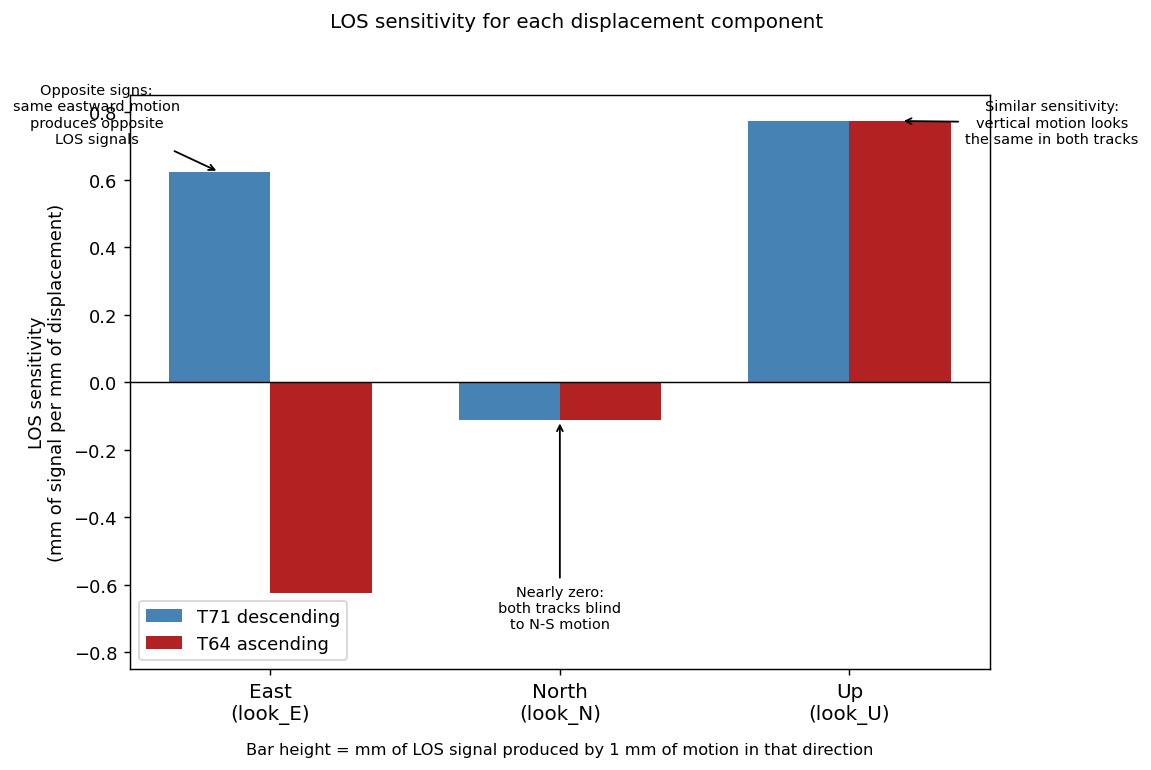

Predicted LOS signal from simple displacement cases:
  1 m eastward motion  → T71: +622 mm  T64: -623 mm
  1 m northward motion → T71: -111 mm  T64: -111 mm
  1 m upward motion    → T71: +774 mm  T64: +774 mm


In [6]:
# Mean look vectors for each track
lv71 = {k: t71[k].mean() for k in ('look_E', 'look_N', 'look_U')}
lv64 = {k: t64[k].mean() for k in ('look_E', 'look_N', 'look_U')}

print('T71 descending mean look vector:')
for k, v in lv71.items(): print(f'  {k}: {v:+.3f}')
print()
print('T64 ascending mean look vector:')
for k, v in lv64.items(): print(f'  {k}: {v:+.3f}')

components = ['East\n(look_E)', 'North\n(look_N)', 'Up\n(look_U)']
vals71 = [lv71['look_E'], lv71['look_N'], lv71['look_U']]
vals64 = [lv64['look_E'], lv64['look_N'], lv64['look_U']]

x = np.arange(3)
w = 0.35

# Make figure taller to give room for title and annotations
fig, ax = plt.subplots(figsize=(9, 6))
ax.bar(x - w/2, vals71, w, label='T71 descending', color='steelblue')
ax.bar(x + w/2, vals64, w, label='T64 ascending',  color='firebrick')
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(components, fontsize=11)
ax.set_ylabel('LOS sensitivity\n(mm of signal per mm of displacement)', fontsize=10)
ax.set_ylim(-0.85, 0.85)
ax.legend(fontsize=10)

# Place title below the figure to avoid collision with annotations above bars
ax.set_xlabel(
    'Bar height = mm of LOS signal produced by 1 mm of motion in that direction',
    fontsize=9, labelpad=10
)

# Annotations — keep text below the top of the axes
ax.annotate('Opposite signs:\nsame eastward motion\nproduces opposite\nLOS signals',
            xy=(0 - w/2, lv71['look_E']), xytext=(-0.6, 0.70),
            arrowprops=dict(arrowstyle='->', color='k'),
            fontsize=8, ha='center', va='bottom')
ax.annotate('Nearly zero:\nboth tracks blind\nto N-S motion',
            xy=(1, lv71['look_N']), xytext=(1.0, -0.60),
            arrowprops=dict(arrowstyle='->', color='k'),
            fontsize=8, ha='center', va='top')
ax.annotate('Similar sensitivity:\nvertical motion looks\nthe same in both tracks',
            xy=(2 + w/2, lv64['look_U']), xytext=(2.7, 0.70),
            arrowprops=dict(arrowstyle='->', color='k'),
            fontsize=8, ha='center', va='bottom')

fig.suptitle('LOS sensitivity for each displacement component', fontsize=11, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Print predicted LOS for a few simple cases
print('Predicted LOS signal from simple displacement cases:')
print(f'  1 m eastward motion  → T71: {lv71["look_E"]*1000:+.0f} mm  '
      f'T64: {lv64["look_E"]*1000:+.0f} mm')
print(f'  1 m northward motion → T71: {lv71["look_N"]*1000:+.0f} mm  '
      f'T64: {lv64["look_N"]*1000:+.0f} mm')
print(f'  1 m upward motion    → T71: {lv71["look_U"]*1000:+.0f} mm  '
      f'T64: {lv64["look_U"]*1000:+.0f} mm')


> **Questions — LOS geometry:**
> 1. Look at the east component of the look vector for both tracks. For a right-lateral NW-SE fault, the two sides of the fault move in roughly opposite east-west directions. Which track would show a stronger signal for this type of fault, and why?
They should have the same signal, but with different signs, since the two tracks are parallel to each other.
> 2. The north component is small and negative for both tracks. The lecture noted that InSAR is relatively insensitive to north-south displacement. Does the look vector confirm this? For a right-lateral fault striking NW-SE, how much of the ground motion is in the north-south direction anyway?
The look vector confirms this, since it has a smaller north-south component. For a right-lateral fault striking NW-SE, this also makes the N-S component of displacement small.
> 3. If a volcano inflated vertically by 10 cm with no horizontal motion, what LOS signal would you predict for each track? Would the two tracks look the same or different?
I would predict a strong positive signal for both tracks, with both producing identical signals.

## Part III: Ascending vs. descending

SAR satellites acquire data on both ascending (south-to-north) and descending (north-to-south) orbital passes. Because Sentinel-1 is right-looking, the two pass directions place the satellite on opposite sides of the scene:

- **Descending (T71):** satellite flies southward, looks right (westward) → satellite is to the **east** of the scene. Eastward ground motion produces positive (red) LOS signal.
- **Ascending (T64):** satellite flies northward, looks right (eastward) → satellite is to the **west** of the scene. Westward ground motion produces positive (red) LOS signal.

You can confirm this from the look vectors: T71 descending has look_E ≈ +0.65 (satellite to the east), while T64 ascending has look_E ≈ −0.65 (satellite to the west). The sign of look_E flips between the two tracks, which means the two tracks respond with opposite signs to the same east-west ground motion.

For the Ridgecrest M7.1 right-lateral NW-SE fault, the dominant horizontal displacement is east-west (east block moves east, west block moves west). Both tracks should show a strong signal, but the color pattern on each side of the fault will be mirror-imaged between the two tracks.


Gridding T64 ... done


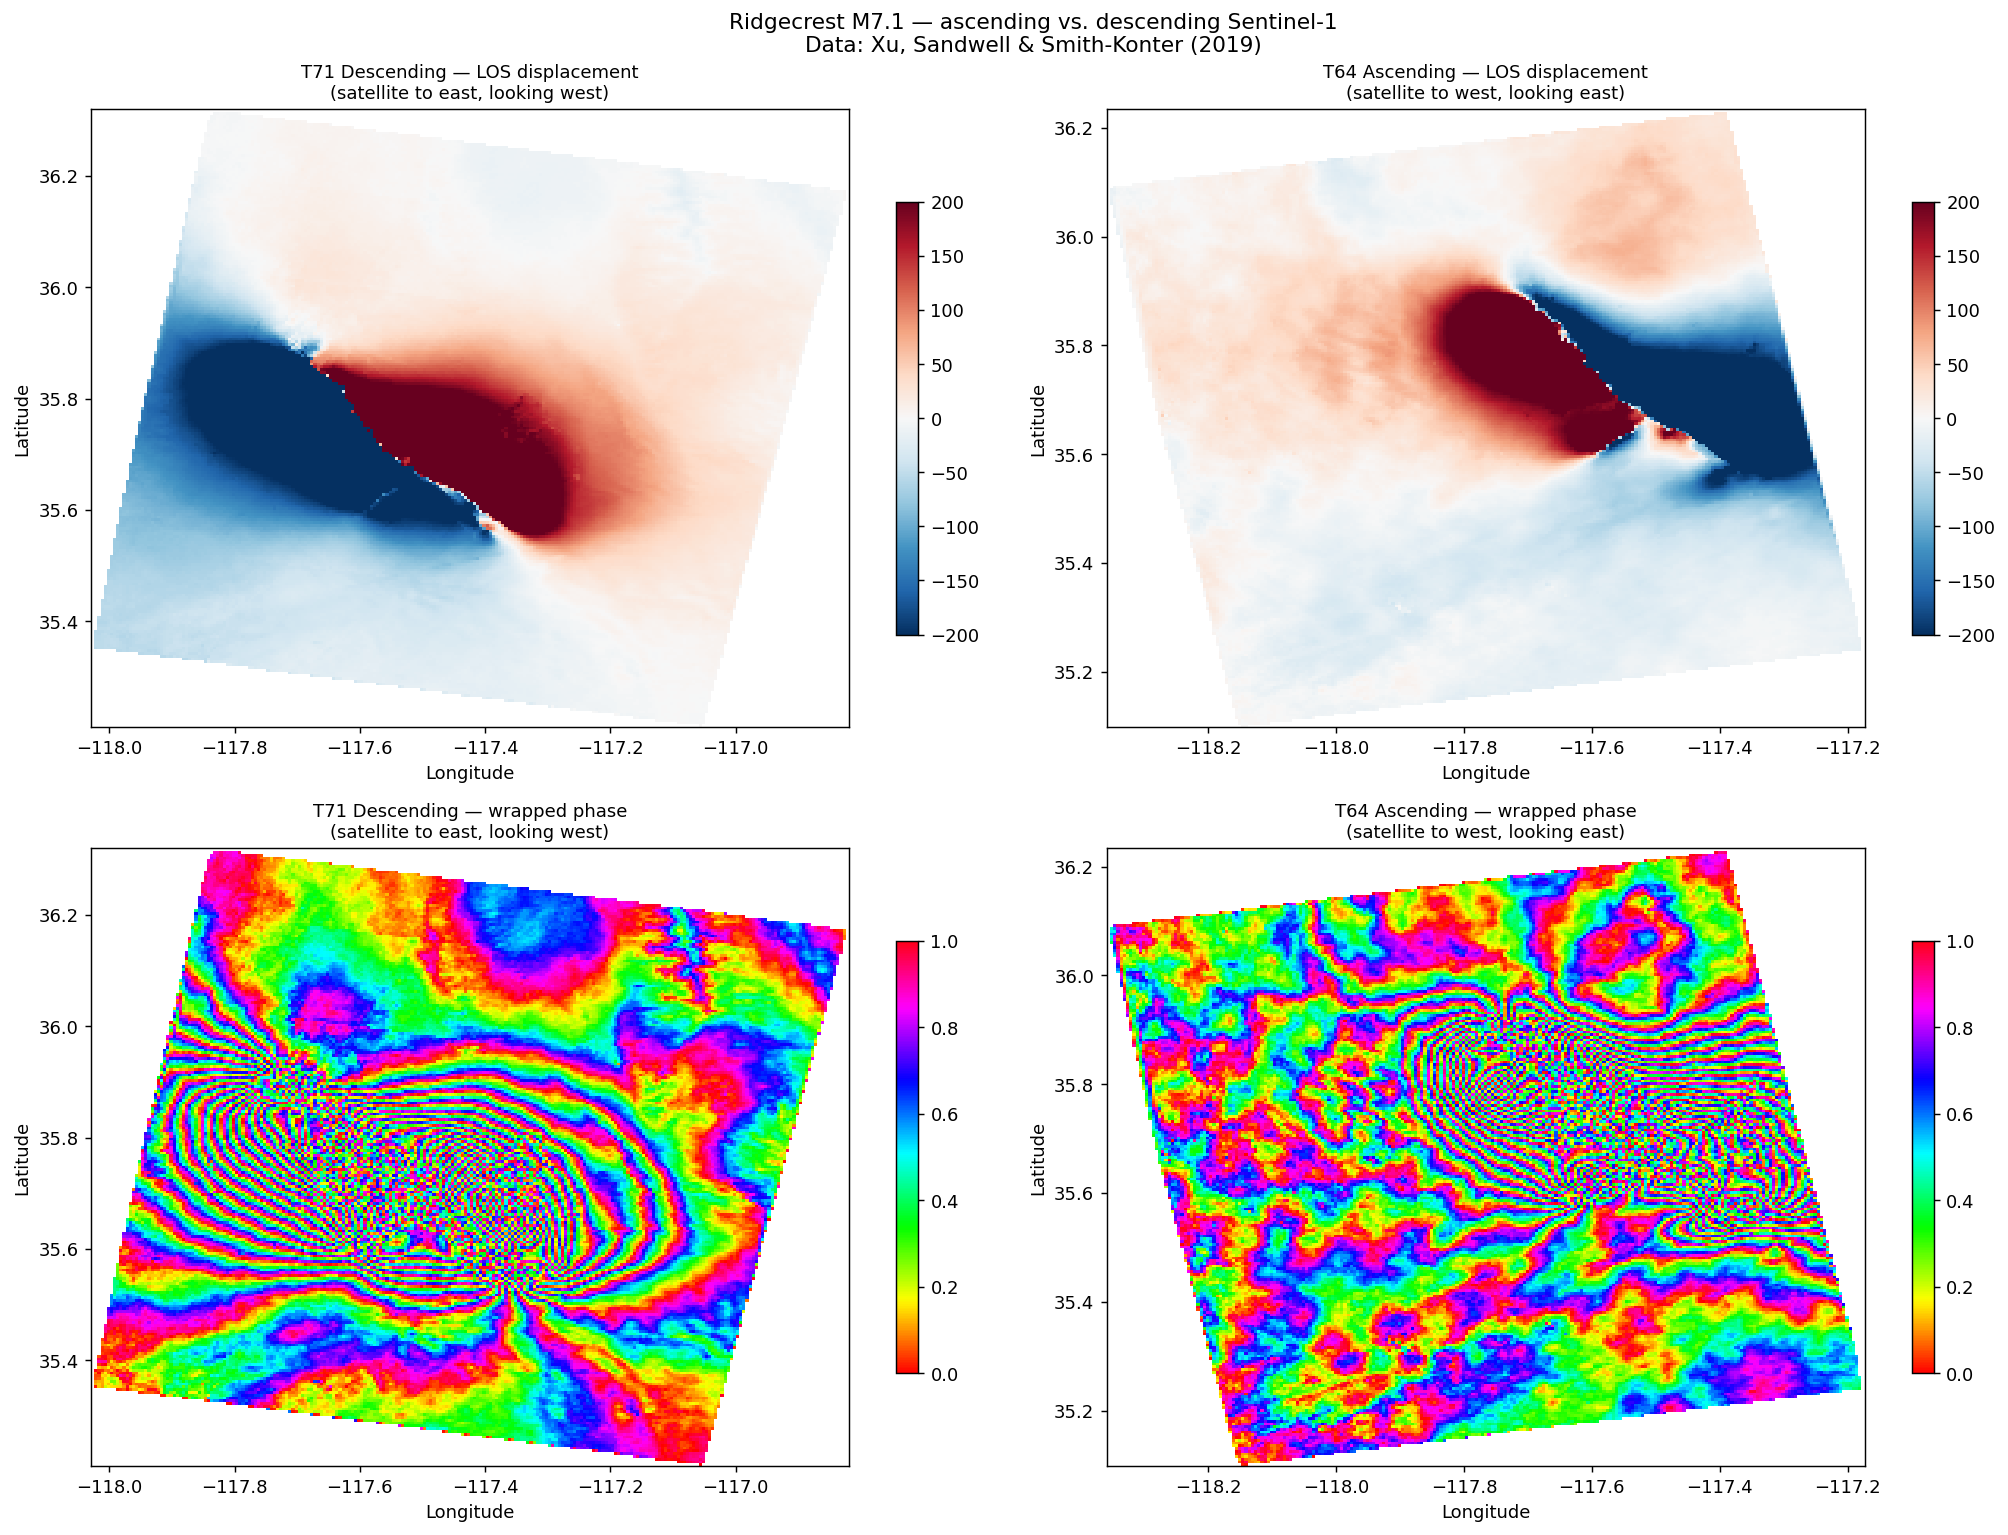

In [7]:
print('Gridding T64 ...', end=' ', flush=True)
LON64, LAT64, DIS64 = grid_los(t64)
print('done')

wrapped64 = (DIS64 / FRINGE_MM) % 1.0

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

plot_args = [
    (axes[0,0], LON71, LAT71, DIS71,     'RdBu_r', -200, 200,
     'T71 Descending — LOS displacement\n(satellite to east, looking west)'),
    (axes[0,1], LON64, LAT64, DIS64,     'RdBu_r', -200, 200,
     'T64 Ascending — LOS displacement\n(satellite to west, looking east)'),
    (axes[1,0], LON71, LAT71, wrapped71, 'hsv',       0,   1,
     'T71 Descending — wrapped phase\n(satellite to east, looking west)'),
    (axes[1,1], LON64, LAT64, wrapped64, 'hsv',       0,   1,
     'T64 Ascending — wrapped phase\n(satellite to west, looking east)'),
]

for ax, LON, LAT, DATA, cmap, vmin, vmax, title in plot_args:
    im = ax.pcolormesh(LON, LAT, DATA, cmap=cmap,
                       vmin=vmin, vmax=vmax, shading='auto')
    plt.colorbar(im, ax=ax, shrink=0.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

plt.suptitle('Ridgecrest M7.1 — ascending vs. descending Sentinel-1\n'
             'Data: Xu, Sandwell & Smith-Konter (2019)', fontsize=12)
plt.tight_layout()
plt.show()


### Decomposing the displacement field

Each InSAR measurement gives one equation relating the three unknown displacement components to the observed LOS value:

$$\Delta\text{LOS} = \hat{e}_E\,\Delta u_E + \hat{e}_N\,\Delta u_N + \hat{e}_U\,\Delta u_U$$

With two tracks we have two equations per pixel:

$$\Delta\text{LOS}_{71} = +0.65\,\Delta u_E - 0.11\,\Delta u_N + 0.74\,\Delta u_U$$
$$\Delta\text{LOS}_{64} = -0.65\,\Delta u_E - 0.11\,\Delta u_N + 0.74\,\Delta u_U$$

Two equations, three unknowns — the system is underdetermined. But the structure of the look vectors tells us a lot about which components are recoverable. The code below works through the algebra explicitly for a pixel near the fault, showing what we can and cannot recover from the two tracks alone.


### Decomposing the displacement field

Each InSAR measurement gives one equation per pixel:

$$\Delta\text{LOS} = \hat{e}_E\,\Delta u_E + \hat{e}_N\,\Delta u_N + \hat{e}_U\,\Delta u_U$$

Substituting the actual look vector values for the two Ridgecrest tracks:

$$\Delta\text{LOS}_{71} = +0.65\,\Delta u_E - 0.11\,\Delta u_N + 0.74\,\Delta u_U$$
$$\Delta\text{LOS}_{64} = -0.65\,\Delta u_E - 0.11\,\Delta u_N + 0.74\,\Delta u_U$$

**Subtract the two equations** — the N and U terms nearly cancel because look_N and look_U are almost the same for both tracks:

$$\Delta\text{LOS}_{71} - \Delta\text{LOS}_{64} \approx 1.30\,\Delta u_E$$

East displacement is well constrained — we can recover it directly from the difference of the two LOS measurements.

**Add the two equations** — the E terms cancel because look_E has opposite signs:

$$\Delta\text{LOS}_{71} + \Delta\text{LOS}_{64} \approx -0.22\,\Delta u_N + 1.48\,\Delta u_U$$

North and up remain **coupled** in the sum — we cannot separate them from InSAR alone because look_N is small and nearly identical for both tracks. Resolving the full 3D displacement field requires a third independent look direction, pixel tracking (which measures along-track displacement and is sensitive to north-south motion), or GNSS point measurements.


> **Questions — ascending vs. descending:**
> 1. Compare the LOS displacement maps for the two tracks. On which side of the fault does each track show red (positive) signal? Is this consistent with the satellite positions stated in the subplot titles?
The descending track shows red on the northeast block, while the descending track shows red on the southwest block, which is consistent with the satellite positions stated in the subplot titles.
> 2. The look_E component has opposite signs for the two tracks (+0.65 vs −0.65). Work through the sign logic: the east block moved eastward. What sign of LOS does this produce in T71? In T64? What about the west block moving westward? Does this explain the mirror-image color pattern?
This produces positive displacement in T71 and negative displacement in T64, with the west block producing negative displacement in T71 and positive displacement in T64, which explains the mirror-image color pattern.
> 3. The decomposition in the section above shows that east displacement is recovered by subtracting the two LOS equations, while north and up remain coupled in the sum. Why are north and up so difficult to separate even with two tracks? What additional observation would let you resolve this ambiguity?
They are difficult to seperate because since the tracks are roughly N - S, the N component of the look direction is quite small.
> 4. The fault strikes 322° (NW-SE), so the slip vector has both east-west and north-south components. Looking at the decomposition equations, the sum of the two LOS measurements is sensitive to north and up while the difference is sensitive to east. Is the sum large or small compared to the difference in the displacement maps? What does this tell you about the relative size of the north-south vs. east-west displacement for this earthquake?
The sum is large compared to the difference in the displacmenet maps, which tells you that the east-west displacement component is larger than the north-south displacement component of this earthquake.


## Part IV: Forward model

Now that you have built intuition from the real data, we will generate a **synthetic interferogram** using elastic dislocation theory and compare it to the observations.

The `cutde` library computes the surface displacement produced by slip on a triangulated fault embedded in an elastic half-space — the same physics as the Okada (1985) model you will use in the inversion lecture. We represent the fault as two triangles forming a rectangle, specify the fault geometry and slip, and compute the east, north, and up displacement at every point in the scene. The synthetic LOS displacement is then:

$$\Delta \text{LOS} = \hat{e}_E \, \Delta u_E + \hat{e}_N \, \Delta u_N + \hat{e}_U \, \Delta u_U$$

using the mean look vector for the T71 descending track.

The fault parameters below are from Barnhart, Hayes & Gold (2019) for the M7.1 mainshock: strike 322°, dip 81°, rake −173° (right-lateral), length ~46 km, slip ~4 m.


In [10]:
def lonlat_to_km(lon, lat, ref_lon, ref_lat):
    """Convert lon/lat to local km (E, N) relative to a reference point."""
    km_lat = 111.0
    km_lon = 111.0 * np.cos(np.radians(ref_lat))
    E = (lon - ref_lon) * km_lon
    N = (lat - ref_lat) * km_lat
    return E, N

def build_fault_triangles(strike_deg, dip_deg, length_km, width_km,
                           depth_top_km, cx_km=0.0, cy_km=0.0):
    """
    Build two triangles representing a rectangular fault, in metres.
    The fault is centred at (cx_km, cy_km) along strike and has its
    top edge at depth depth_top_km.
    """
    s = np.radians(strike_deg)
    d = np.radians(dip_deg)

    # Along-strike unit vector [E, N, U]
    along = np.array([np.sin(s), np.cos(s), 0.0])

    # Down-dip unit vector [E, N, U]
    # The dip direction is 90 degrees clockwise from the strike (right-hand rule)
    # dip_azimuth = strike + 90 deg
    down = np.array([np.cos(s) * np.cos(d),
                     -np.sin(s) * np.cos(d),
                     -np.sin(d)])

    # Four corners of the fault rectangle
    top_centre = np.array([cx_km, cy_km, -depth_top_km])
    c0 = top_centre - along * (length_km / 2)    # top left
    c1 = top_centre + along * (length_km / 2)    # top right
    c2 = c1 + down * width_km                     # bottom right
    c3 = c0 + down * width_km                     # bottom left

    # Two triangles; convert km → metres for cutde
    tris = np.array([[c0, c1, c2],
                     [c0, c2, c3]], dtype=float) * 1000
    return tris

def compute_synthetic_los(strike, dip, rake, length_km, width_km,
                           depth_top_km, slip_m,
                           ref_lon, ref_lat,
                           obs_lon, obs_lat,
                           look_E, look_N, look_U):
    """
    Compute synthetic LOS displacement (mm) using cutde.

    Slip is in fault-local coordinates [strike-slip, dip-slip, opening]
    following the Okada convention:
      positive strike-slip = left-lateral
      positive dip-slip    = reverse/thrust
    For rake, cos(rake) gives the strike-slip component and
    sin(rake) gives the dip-slip component.
    """
    tris = build_fault_triangles(strike, dip, length_km, width_km, depth_top_km)

    # Slip in fault-local coordinates [strike-slip, dip-slip, opening] in metres
    rake_rad = np.radians(rake)
    slip_vec = np.array([np.cos(rake_rad), np.sin(rake_rad), 0.0]) * slip_m
    slips = np.tile(slip_vec, (2, 1))   # same slip on both triangles, shape (2, 3)

    # Observation points at the surface (z=0), in metres
    obs_E, obs_N = lonlat_to_km(obs_lon.ravel(), obs_lat.ravel(), ref_lon, ref_lat)
    obs_pts = np.column_stack([obs_E * 1000,
                                obs_N * 1000,
                                np.zeros(len(obs_E))])

    # Compute 3D surface displacement (metres)
    disp = hs.disp_free(obs_pts, tris, slips, 0.25)   # Poisson ratio = 0.25

    dE = disp[:, 0].reshape(obs_lon.shape)
    dN = disp[:, 1].reshape(obs_lon.shape)
    dU = disp[:, 2].reshape(obs_lon.shape)

    # Project onto LOS direction, convert to mm
    los = (look_E * dE + look_N * dN + look_U * dU) * 1000
    return los

# Ridgecrest M7.1 fault parameters (Barnhart et al. 2019)
PARAMS = dict(
    strike=322, dip=81, rake=-173,
    length_km=46, width_km=18, depth_top_km=0.5,
    slip_m=2.0,
)
REF_LON, REF_LAT = -117.55, 35.70   # approximate fault centre

lE = t71['look_E'].mean()
lN = t71['look_N'].mean()
lU = t71['look_U'].mean()

print('Computing synthetic interferogram ...', end=' ', flush=True)
syn71 = compute_synthetic_los(
    **PARAMS, ref_lon=REF_LON, ref_lat=REF_LAT,
    obs_lon=LON71, obs_lat=LAT71,
    look_E=lE, look_N=lN, look_U=lU,
)
print('done')
print(f'Synthetic LOS range: [{syn71[~np.isnan(syn71)].min():.0f}, '
      f'{syn71[~np.isnan(syn71)].max():.0f}] mm')


Computing synthetic interferogram ... done
Synthetic LOS range: [-352, 621] mm


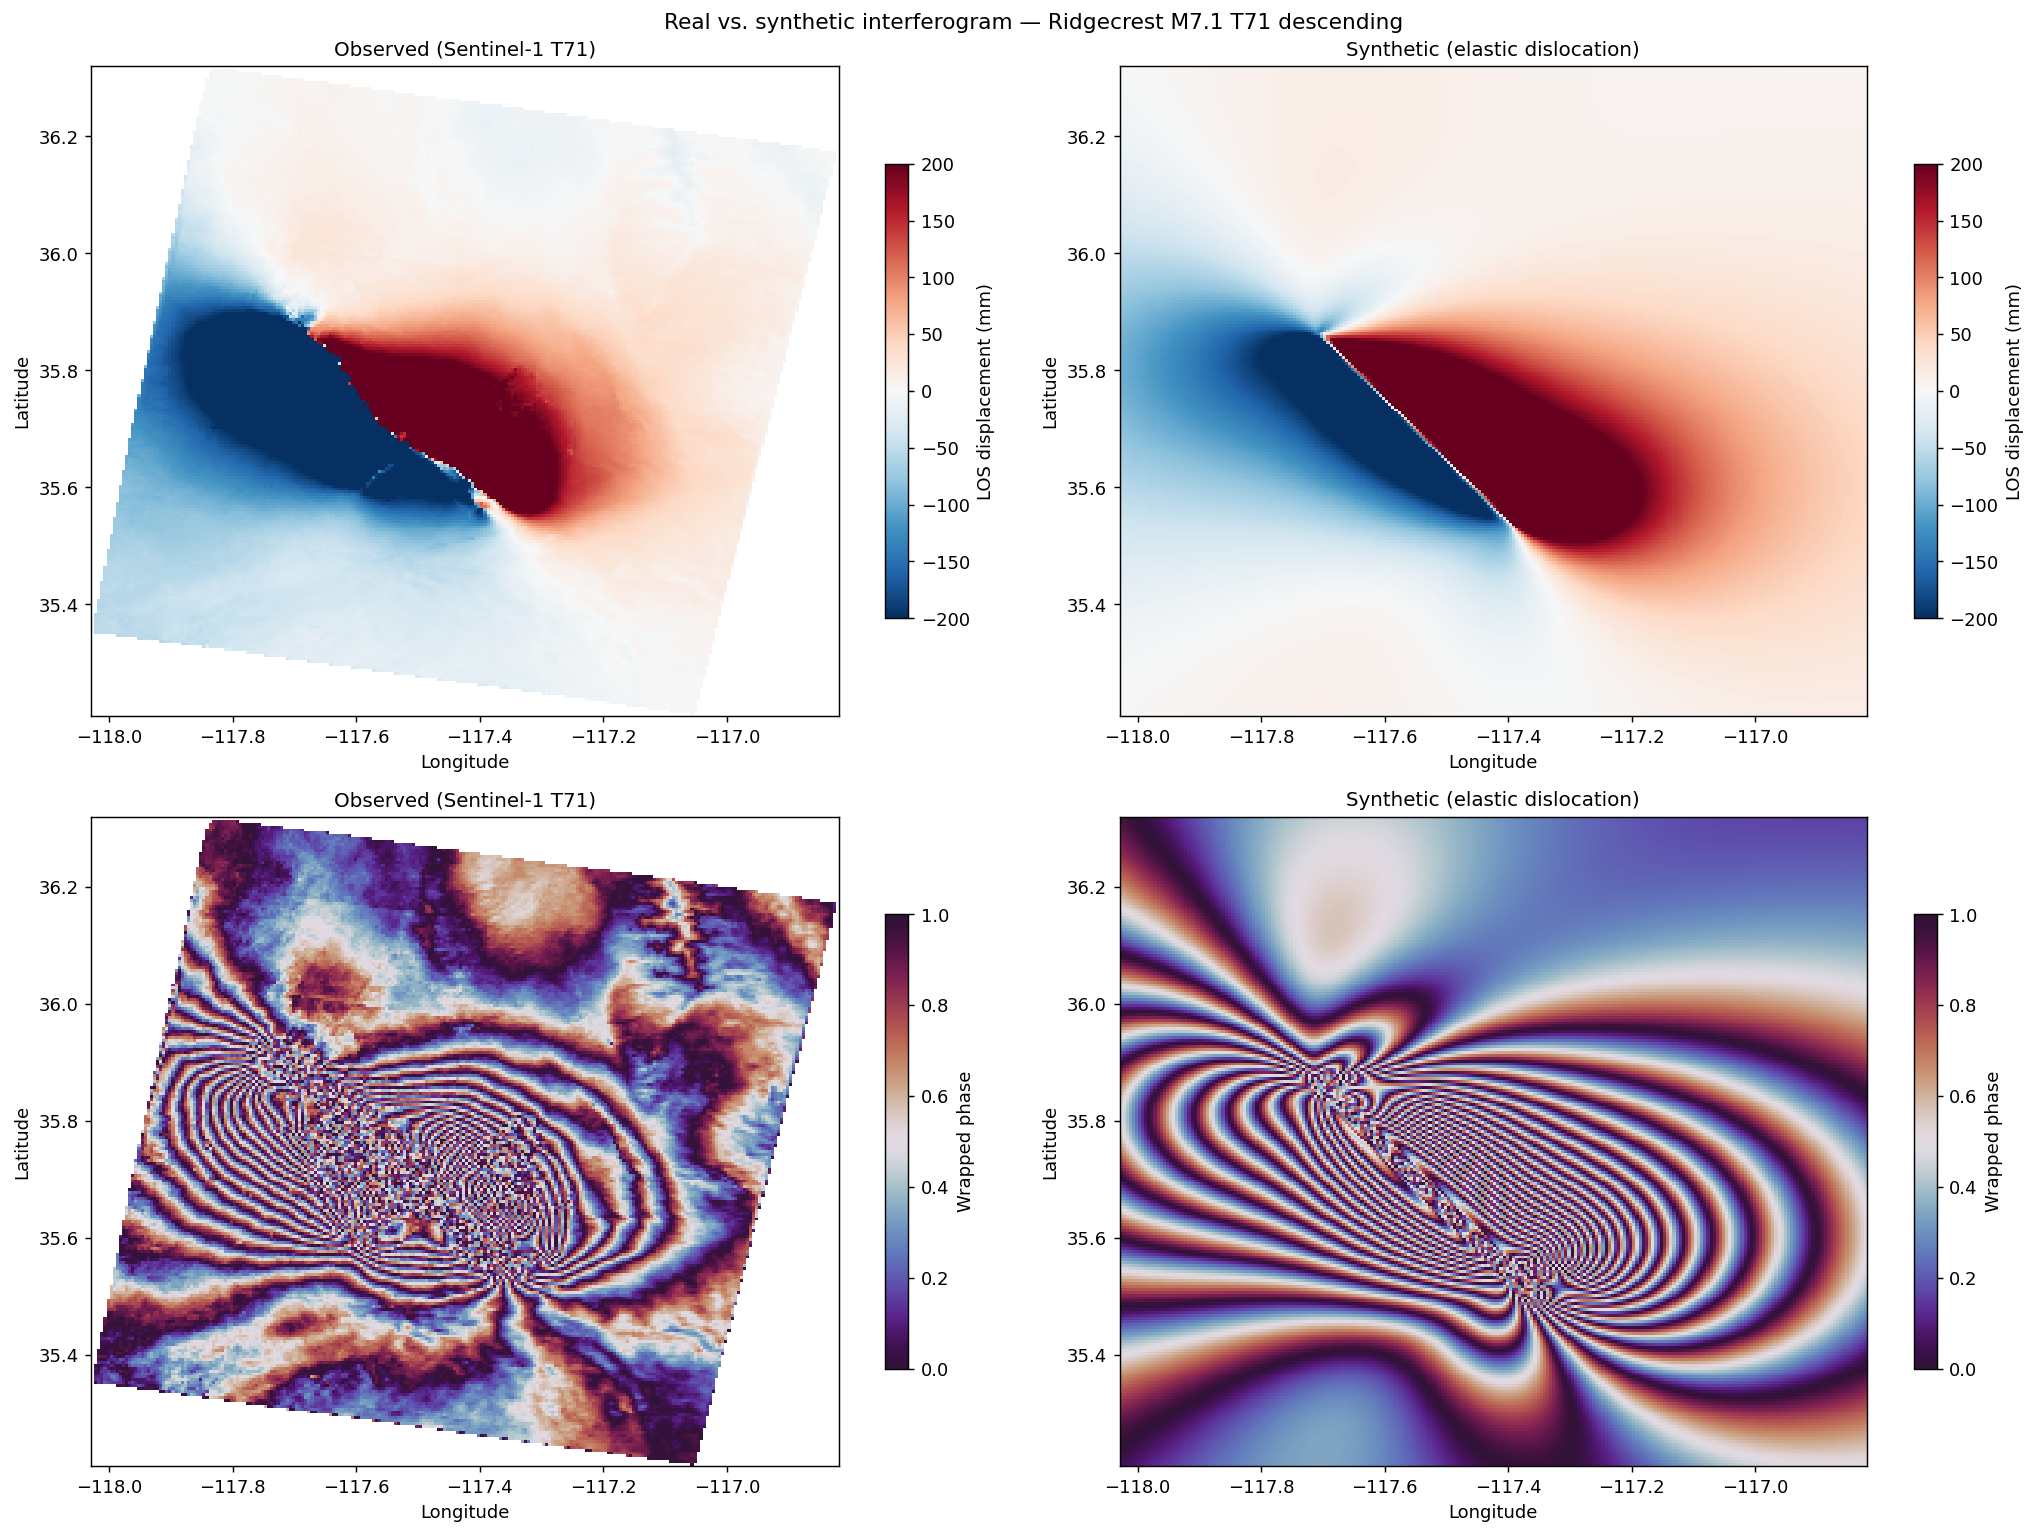

In [11]:
wrapped_syn = (syn71 / FRINGE_MM) % 1.0

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

rows = [
    (DIS71,      syn71,      'RdBu_r',        -200, 200, 'LOS displacement (mm)'),
    (wrapped71,  wrapped_syn,'twilight_shifted', 0,   1, 'Wrapped phase'),
]

for row_idx, (real, syn, cmap, vmin, vmax, clabel) in enumerate(rows):
    for col_idx, (data, subtitle) in enumerate([
        (real, 'Observed (Sentinel-1 T71)'),
        (syn,  'Synthetic (elastic dislocation)'),
    ]):
        ax = axes[row_idx, col_idx]
        im = ax.pcolormesh(LON71, LAT71, data, cmap=cmap,
                           vmin=vmin, vmax=vmax, shading='auto')
        plt.colorbar(im, ax=ax, shrink=0.7, label=clabel)
        ax.set_title(subtitle, fontsize=11)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

plt.suptitle('Real vs. synthetic interferogram — Ridgecrest M7.1 T71 descending',
             fontsize=12)
plt.tight_layout()
plt.show()


> **Questions — forward model:**
> 1. Compare the real and synthetic LOS displacement maps. Describe the main similarities and differences in the overall pattern and the fringe count.
The general shape of the wrapped and unwrapped displacements is very similar, but there appears to be a higher fringe count in the synthetic displacements, and a larger coherent region, with no influence from deformation attributed to the Ridgecrest foreshock.
> 2. The synthetic model assumes a single planar fault with uniform slip. The real data shows some asymmetry and complexity near the fault trace, particularly in the southern half of the rupture. What might explain the differences?
Again, the intersecting fault responsible for the M6.4 foreshock, as well as distributed deformation near the surface in the form of secondary faults and fractures, and liquefaction features.
> 3. Try changing the slip magnitude in the PARAMS dictionary and re-running the forward model. How does the number of fringes change? What does this tell you about using fringe counts to estimate earthquake slip magnitude?
A reduction in slip by a factor of 2 also reduced the fringes by a factor of 2. This means that fringe counts are a good estimator of coseismic displacement.
> 4. The M6.4 foreshock also contributed to the displacement field in the real data. Where in the scene would you expect the M6.4 signal to appear, and how might it affect your fringe count comparison?
I would expect it to appear as a NE - SW striking band of fringes near the location of maximum displacement on the mainshock, which would locally increase the number of fringes.


## Part V: Profile and GNSS comparison

A cross-fault displacement profile — a slice through the LOS displacement map perpendicular to the fault — is one of the most effective ways to quantify coseismic slip and compare InSAR to other geodetic observations.

The shape of the profile depends critically on whether the fault ruptured the surface. The Ridgecrest M7.1 did rupture the surface with 2–5 m of right-lateral offset visible in the field. For a surface-rupturing fault the coseismic profile shows a **sharp step** right at the fault trace — displacement jumps abruptly from one plateau on the east side to another on the west side, because slip extended all the way to the surface. Away from the fault the displacement decays smoothly toward zero in the far field. This is quite different from the arctangent shape of an interseismic profile (the Savage-Burford model), which describes a locked fault accumulating strain between earthquakes rather than the coseismic rupture itself.

We extract a profile perpendicular to the M7.1 fault (which strikes 322°, so the profile runs at 52° — SW to NE), selecting all InSAR pixels within a 10 km swath. We then compare these LOS observations to the GNSS coseismic offsets from Lab 4, projecting each GNSS station's 3D displacement vector onto the same LOS direction using the look vector at that station's location.


InSAR pixels in profile swath: 10,371


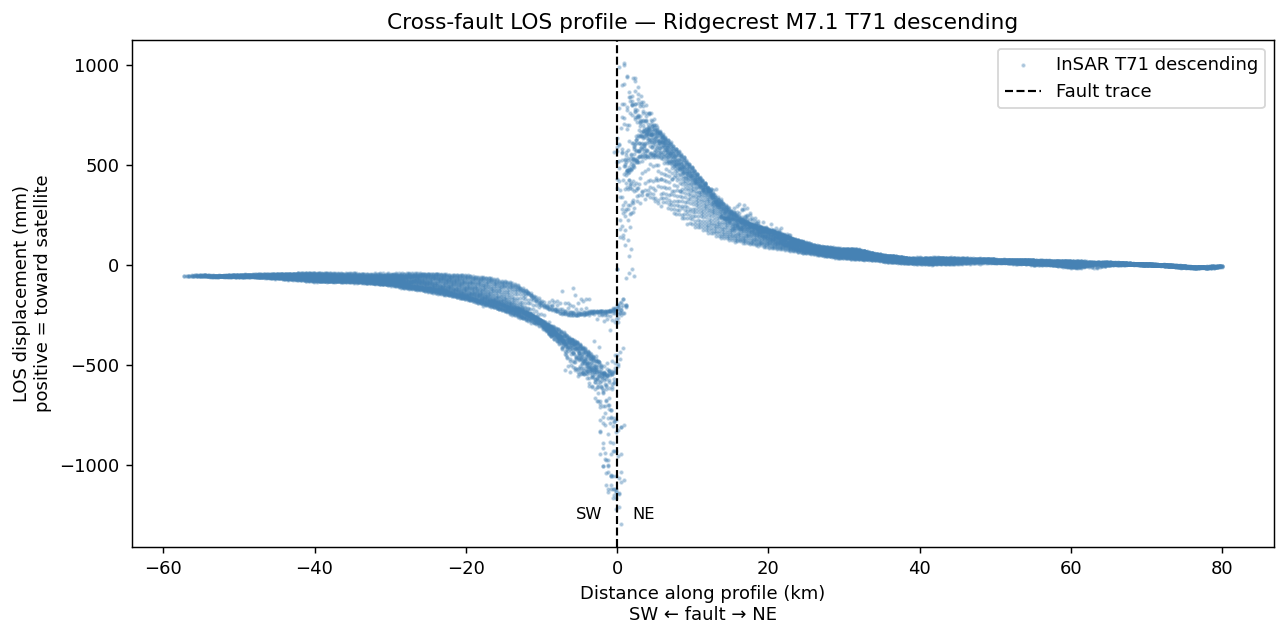

In [12]:
# Profile geometry: perpendicular to the M7.1 fault (strike 322 deg)
# Profile azimuth: 52 deg from North (NE direction)
PROF_LON, PROF_LAT = -117.55, 35.70   # profile centre on the fault
PROF_AZ   = 52.0                       # degrees from North
SWATH_KM  = 10.0                       # half-width of the swath
PROF_LEN  = 80.0                       # half-length of the profile (km)

az_rad  = np.radians(PROF_AZ)
pE = np.sin(az_rad)    # profile unit vector (East)
pN = np.cos(az_rad)    # profile unit vector (North)

def to_local_km(lon, lat):
    E = (lon - PROF_LON) * 111.0 * np.cos(np.radians(PROF_LAT))
    N = (lat - PROF_LAT) * 111.0
    return E, N

# InSAR profile
E71, N71 = to_local_km(t71['lon'], t71['lat'])
along_71 =  pE * E71 + pN * N71
perp_71  = -pN * E71 + pE * N71
mask71   = (np.abs(perp_71) < SWATH_KM) & (np.abs(along_71) < PROF_LEN)

print(f'InSAR pixels in profile swath: {mask71.sum():,}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(along_71[mask71], t71['disp'][mask71],
           c='steelblue', s=2, alpha=0.3, label='InSAR T71 descending')
ax.axvline(0, color='k', lw=1.2, ls='--', label='Fault trace')
ax.text(-2, ax.get_ylim()[0]*0.9, 'SW', ha='right', fontsize=9)
ax.text( 2, ax.get_ylim()[0]*0.9, 'NE', ha='left',  fontsize=9)
ax.set_xlabel('Distance along profile (km)\nSW ← fault → NE')
ax.set_ylabel('LOS displacement (mm)\npositive = toward satellite')
ax.set_title('Cross-fault LOS profile — Ridgecrest M7.1 T71 descending')
ax.legend()
plt.tight_layout()
plt.show()


GNSS stations within InSAR footprint: 14


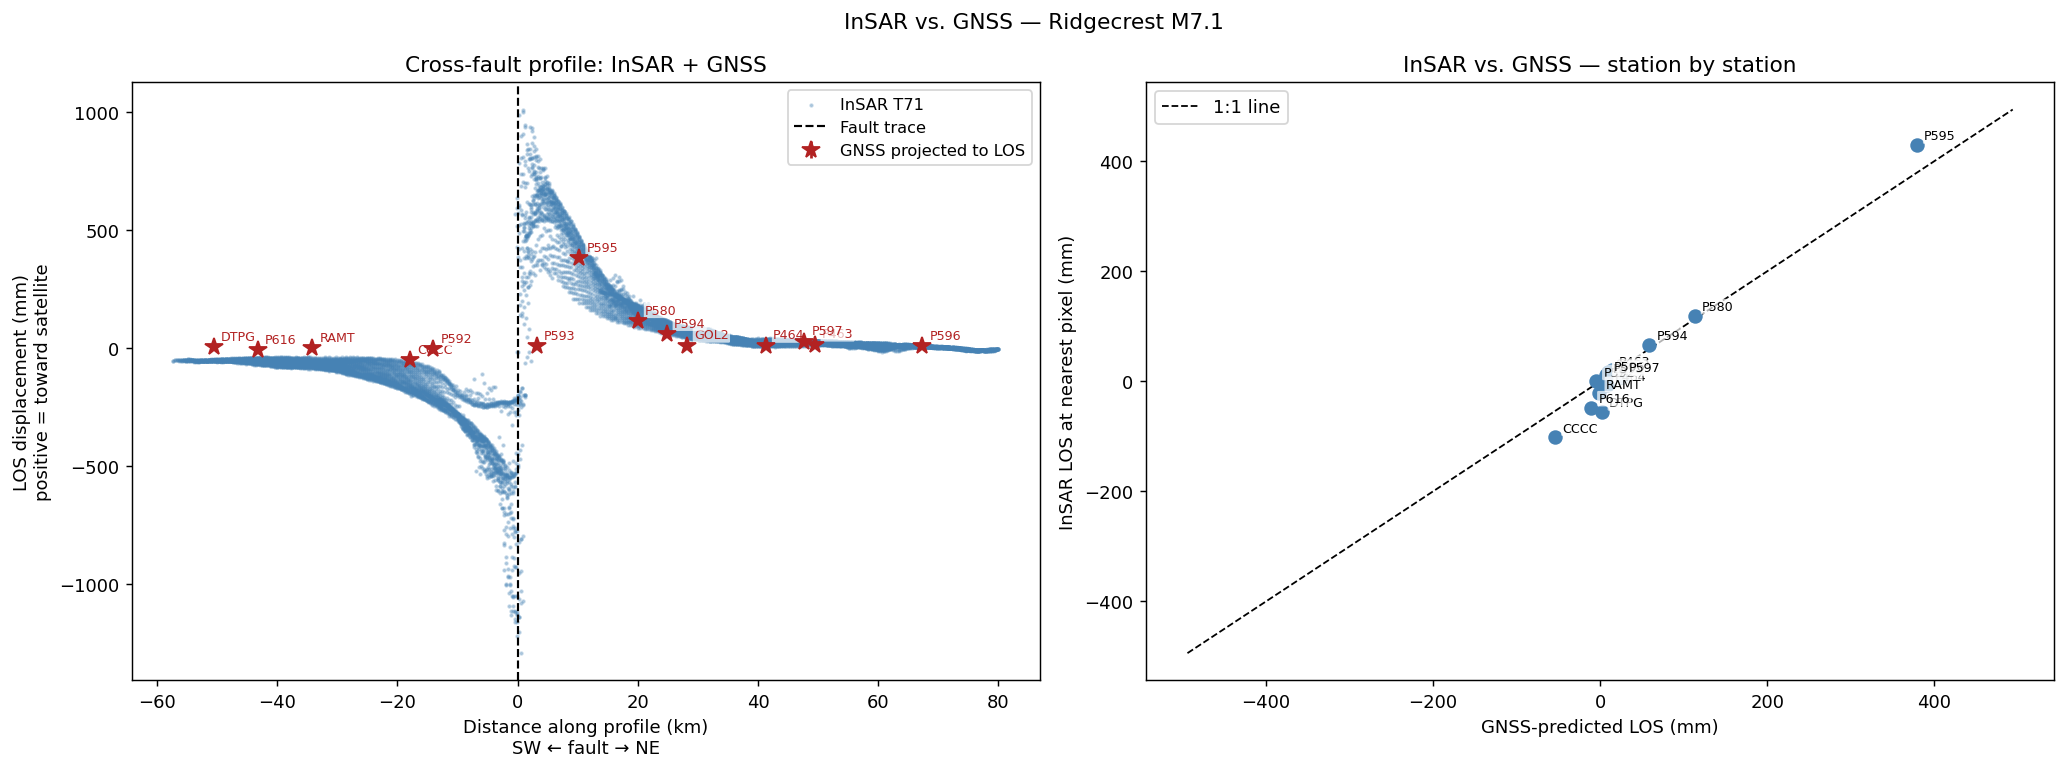

In [13]:
# Load GNSS coseismic offsets (Lab 4)
gnss_raw = np.genfromtxt(local['gnss'], skip_header=2, dtype=None, encoding=None,
                          names=['sta','lon','lat','de','dn','du','sde','sdn','sdu'])

# Filter to stations within the InSAR footprint
lon_min, lon_max = t71['lon'].min(), t71['lon'].max()
lat_min, lat_max = t71['lat'].min(), t71['lat'].max()
in_footprint = ((gnss_raw['lon'] > lon_min) & (gnss_raw['lon'] < lon_max) &
                (gnss_raw['lat'] > lat_min) & (gnss_raw['lat'] < lat_max))
gnss = gnss_raw[in_footprint]
print(f'GNSS stations within InSAR footprint: {len(gnss)}')

# For each GNSS station find the nearest InSAR pixel and get its look vector
tree = cKDTree(np.column_stack([t71['lon'], t71['lat']]))
_, idx = tree.query(np.column_stack([gnss['lon'], gnss['lat']]))

# Project GNSS 3D displacement onto InSAR LOS direction (mm)
gnss_los = (t71['look_E'][idx] * gnss['de'] * 1000 +
            t71['look_N'][idx] * gnss['dn'] * 1000 +
            t71['look_U'][idx] * gnss['du'] * 1000)
gnss_los_err = np.sqrt((t71['look_E'][idx] * gnss['sde'] * 1000)**2 +
                        (t71['look_N'][idx] * gnss['sdn'] * 1000)**2 +
                        (t71['look_U'][idx] * gnss['sdu'] * 1000)**2)

# Profile distance for each GNSS station
gE, gN = to_local_km(gnss['lon'], gnss['lat'])
gnss_along = pE * gE + pN * gN
gnss_perp  = -pN * gE + pE * gN

# Observed InSAR LOS at nearest pixel to each GNSS station
insar_at_gnss = t71['disp'][idx]

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: cross-fault profile with GNSS overlay
axes[0].scatter(along_71[mask71], t71['disp'][mask71],
                c='steelblue', s=2, alpha=0.3, label='InSAR T71')
axes[0].errorbar(gnss_along, gnss_los, yerr=gnss_los_err,
                 fmt='*', color='firebrick', ms=10, lw=1.5, zorder=5,
                 label='GNSS projected to LOS')

# Label each GNSS station
for i, sta in enumerate(gnss['sta']):
    axes[0].annotate(
        sta,
        xy=(gnss_along[i], gnss_los[i]),
        xytext=(4, 4), textcoords='offset points',
        fontsize=7, color='firebrick',
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white',
                  edgecolor='none', alpha=0.7),
    )

axes[0].axvline(0, color='k', lw=1.2, ls='--', label='Fault trace')
axes[0].set_xlabel('Distance along profile (km)\nSW ← fault → NE')
axes[0].set_ylabel('LOS displacement (mm)\npositive = toward satellite')
axes[0].set_title('Cross-fault profile: InSAR + GNSS')
axes[0].legend(fontsize=9)

# Right: direct InSAR vs GNSS scatter at each station
lim = max(np.abs(insar_at_gnss).max(), np.abs(gnss_los).max()) * 1.15
axes[1].errorbar(gnss_los, insar_at_gnss, xerr=gnss_los_err,
                 fmt='o', color='steelblue', ms=7, lw=1.5)
axes[1].plot([-lim, lim], [-lim, lim], 'k--', lw=1, label='1:1 line')
# Label every station
for i, sta in enumerate(gnss['sta']):
    axes[1].annotate(
        sta,
        xy=(gnss_los[i], insar_at_gnss[i]),
        xytext=(4, 3), textcoords='offset points',
        fontsize=7,
        bbox=dict(boxstyle='round,pad=0.1', facecolor='white',
                  edgecolor='none', alpha=0.7),
    )
axes[1].set_xlabel('GNSS-predicted LOS (mm)')
axes[1].set_ylabel('InSAR LOS at nearest pixel (mm)')
axes[1].set_title('InSAR vs. GNSS — station by station')
axes[1].legend()

plt.suptitle('InSAR vs. GNSS — Ridgecrest M7.1', fontsize=12)
plt.tight_layout()
plt.show()


> **Questions — profile and GNSS comparison:**
> 1. Describe the shape of the InSAR LOS profile across the fault. Is the transition at the fault trace sharp or gradual? How does this relate to whether the fault ruptured the surface? How does the coseismic profile differ from the interseismic arctangent shape you would expect for a locked fault accumulating strain between earthquakes?
The transition is sharp, showing the fault ruptured to the surface. The coseismic profile is the inverse of the interseismic arctangent profile which reflects accumulation of elastic strain.
> 2. How well do the GNSS-predicted LOS values agree with the InSAR observations at the same locations? Where do they agree best? Are there any stations that stand out as outliers — can you identify them by name on the profile — and can you think of a reason why they might disagree?
They agree well with InSAR observations, most notably in the far field on the northeast block of the fault. P592 and P593 seem to stand out the most, which could be because they measured coseismic displacement while InSAR measured 10 days of surface deformation.
> 3. InSAR gives millions of measurements across the entire scene while the nearby GNSS network provides only a handful of point measurements. What does each technique offer that the other cannot? In what situation would you trust GNSS over InSAR?
InSAR gives more displacement measurements at a higher spatial resolution, but GNSS gives reliable displacement measurements in all three components without the need for inversion. Additionally, GNSS does not fall victim to most of the soures of noise that InSAR does. I would trust GNSS over InSAR in a region with strong transients or abundant vegetation.
> 4. The InSAR data spans 4–16 July, capturing both the M6.4 and M7.1 events plus ~10 days of postseismic deformation. The GNSS offsets are estimated as a static step at the time of each earthquake. How might this difference in time window affect the comparison, and where in the scene would you expect the effect to be largest?
This means that we would expect InSAR to measure more deformation in all components, due to contributions from viscoelastic relaxation, poroelastic strain, and postseismic creep. I would expect these effects to be largest in the farfield, depending on the magnitude of the postseismic creep (more postseismic creep would mean a stronger displacement signal in the near field).

## Synthesis

Answer each of the following in 2–3 sentences.

> **1. Reading interferograms.** A colleague shows you a new interferogram of an unknown earthquake. What steps would you take to determine the fault type, estimate the slip magnitude, and assess whether the fault ruptured the surface?
I would need to know the components of the look vector to know the slip sense of the fault, and could estimate the magnitude of the displacement using the radar wavelength combined with the number of fringes adjacent to the fault. A cross-fault profile of the InSAR data would give a clear picture of whether the fault ruptured the surface depending on whether it was a sharp or gradational transition between displacements across the fault, with the caveat that it might not be possible to distinguish between coseismic slip and postseismic surface creep, depending on your temporal resolution.
> **2. Viewing geometry.** Your colleague only has an ascending track. What can they determine confidently, and what ambiguity remains? What does adding a descending track resolve?
They can confidently determine east - west components of displacement, as these should be equal and opposite with a descending track, but they will not be able to resolve up or north - south components. Adding a descending track allows you to isolate north and up components and then solve for them independently. However, the amount of coseismic slip and therefore magnitude remains undetermined, since these data may have not been collected for days after the event.

> **3. InSAR and GNSS.** Why are InSAR and GNSS complementary rather than redundant? What would a seismologist miss by relying on only one?
Again, coseismic slip measurements from GNSS are more reliable than those from InSAR, leading to more accurate magntiude inversions from GNSS than one might get from InSAR. However, GNSS data are spatially limited, which means InSAR allows a more accurate measurement of rupture length, and allows you to resolve the fault plane from the auxiliary plane. Additionally, a seismologist could show more concrete evidence of surface slip from a InSAR profile than one built with the more limited GNSS stations. InSAR's resolution also allows relocation of surface displacements to asperities at depth, but in earthquake sequences that are too close in time and space for InSAR to differentiate, GNSS will allow the resolution of the independent displacements from each event, and inversions of their locations.

> **4. Noise.** An interferogram of a volcano shows a broad smooth fringe pattern that could be magma chamber inflation or atmospheric delay. Propose two ways to distinguish between them.
One way to differentiate between the signals is to make interferograms using measurements taken at different times or over different timescales. Another way would be to compare these readings to those taken by GNSS stations or tiltmeters, if available. In some cases, using longer radar wavelengths could isolate some of the noise.


## Summary

- **InSAR measures line-of-sight (LOS) displacement** — the component of ground motion toward or away from the satellite. Each fringe in a C-band interferogram represents 2.8 cm of LOS displacement (half the radar wavelength).
- **The LOS unit vector** (look_E, look_N, look_U) determines how each component of displacement contributes to the InSAR signal. InSAR is most sensitive to east-west and vertical motion and relatively insensitive to north-south displacement.
- **Ascending and descending tracks** sample different components of the displacement field. Combining them allows partial decomposition of 3D motion and helps resolve ambiguities in fault geometry.
- **Elastic dislocation forward models** (Okada 1985; `cutde`) can reproduce the main features of observed interferograms from fault parameters alone, providing a direct link between the fringe pattern and the underlying fault geometry and slip.
- **InSAR and GNSS are complementary:** InSAR provides dense spatial coverage but integrates all motion during the satellite repeat interval; GNSS provides precise 3D point measurements at discrete stations.
- **Sources of noise** — atmospheric water vapor delay and decorrelation — can mimic or mask real deformation signals and must be assessed in any InSAR study.
